In [2]:
# %%
# ============================================================
# 0. Imports e Configuração Global
# ============================================================

import os
import warnings
import time
from dataclasses import dataclass
from glob import glob

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.fft as fft

from scipy.io import loadmat
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

try:
    from tqdm.auto import tqdm
except ImportError:
    from tqdm import tqdm

try:
    import pywt
except ImportError:
    !pip install PyWavelets -q
    import pywt

# Reprodutibilidade
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [3]:
# %%
# ============================================================
# 1. Dataset MRI (BIRN)
# ============================================================

class MRIDataset(torch.utils.data.Dataset):
    """Carrega volumes .mat e extrai fatias 2D normalizadas para [0,1]."""
    def __init__(self, root):
        self.files = sorted(glob(os.path.join(root, "**", "*.mat"), recursive=True))
        if not self.files:
            raise RuntimeError(f"Nenhum arquivo .mat encontrado em {root}")

        self.images = []
        print("Lendo arquivos...")
        for file in tqdm(self.files):
            mat = loadmat(file)
            volume = None
            for key, value in mat.items():
                if key.startswith("__"):
                    continue
                if isinstance(value, np.ndarray) and value.ndim == 3:
                    volume = value.astype(np.float32)
                    break
            if volume is None:
                continue

            # Detecta orientação: (H,W,N) ou (N,H,W)
            if volume.shape[0] == volume.shape[1]:      # (H,W,N)
                for i in range(volume.shape[2]):
                    self.images.append(volume[:, :, i])
            else:                                       # (N,H,W)
                for i in range(volume.shape[0]):
                    self.images.append(volume[i])

        # Normalização global para [0,1]
        for i in range(len(self.images)):
            img = self.images[i]
            img = img - img.min()
            img = img / (img.max() + 1e-8)
            self.images[i] = img

        print(f"Total de slices carregadas: {len(self.images)}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return torch.from_numpy(self.images[idx]).float()

# Defina o caminho do dataset
dataset_path = "/kaggle/input/datasets/semnickcharlie/brain-dataset1"  # Ajuste aqui

try:
    dataset = MRIDataset(dataset_path)
except Exception as e:
    print(f"Erro ao carregar: {e}. Usando dataset sintético para demonstração.")
    class DummyDataset:
        def __init__(self, n=30):
            self.images = [np.random.rand(128, 128).astype(np.float32) for _ in range(n)]
            for i in range(n):
                self.images[i] = (self.images[i] - self.images[i].min()) / (self.images[i].max() + 1e-8)
        def __len__(self):
            return len(self.images)
        def __getitem__(self, idx):
            return torch.from_numpy(self.images[idx])
    dataset = DummyDataset(30)

Lendo arquivos...


  0%|          | 0/158 [00:00<?, ?it/s]

Total de slices carregadas: 4020


In [4]:
# %%
# ============================================================
# 2. Configuração do CS e Máscara Radial (com T_REF fixo)
# ============================================================

@dataclass
class CSConfig:
    # Wavelet
    wavelet: str = "db4"
    level: int = 3

    # Regularização (valores iniciais para continuação)
    lambda_wavelet_start: float = 0.008
    lambda_wavelet_end: float = 0.002
    lambda_tv_start: float = 0.003
    lambda_tv_end: float = 0.0005

    # Continuação
    use_continuation: bool = True
    schedule: str = "cosine"

    # Otimização
    max_iter: int = 150
    tolerance: float = 1e-6
    restart: bool = True

    # TV interna (5 iterações para acelerar)
    tv_inner_iter: int = 5
    verbose: bool = False

# Constante de referência para a máscara (escala máxima)
# Quanto maior T_REF, mais "suave" é a variação do número de raios
T_REF = 100  # valor fixo global

def create_mask_t(shape, t, T_ref, device, seed=None):
    """
    Máscara radial com t variando de 0 a T_ref.
    t=0 → poucos raios (alta aceleração)
    t=T_ref → muitos raios (baixa aceleração)

    Args:
        shape: (H, W) da imagem
        t: valor atual (0 a T_ref) que controla o número de raios
        T_ref: constante de referência (fixa, ex: 100)
        device: dispositivo (cuda/cpu)
        seed: semente para reprodutibilidade (opcional)
    """
    if seed is not None:
        torch.manual_seed(seed)

    H, W = shape
    if torch.is_tensor(t):
        t = t.item()

    # alpha = 0 → poucos raios, alpha = 1 → muitos raios
    alpha = t / T_ref
    alpha = max(0.0, min(1.0, alpha))  # garante [0,1]
    alpha_eff = alpha ** 1.5
    max_spokes = H
    min_spokes = 24
    num_spokes = int(max_spokes - alpha_eff * (max_spokes - min_spokes))
    num_spokes = max(min_spokes, num_spokes)

    mask = torch.zeros(H, W, device=device)
    cy, cx = H // 2, W // 2
    y, x = torch.meshgrid(torch.arange(H, device=device),
                          torch.arange(W, device=device),
                          indexing="ij")
    y = y - cy
    x = x - cx

    # Desenha os raios
    for i in range(num_spokes):
        theta = i * np.pi / num_spokes
        distance = torch.abs(x * np.sin(theta) - y * np.cos(theta))
        mask[distance < 1.5] = 1

    # Região central calibrada (10x10) sempre totalmente amostrada
    r2 = x**2 + y**2
    mask[r2 <= 10**2] = 1
    return mask

print(f"T_REF global = {T_REF}")

T_REF global = 100


In [5]:
# %%
# ============================================================
# 3. Operadores Lineares (Fourier, Wavelet, TV)
# ============================================================

class MRIOperator:
    """Operador A = M * F (com norm='ortho')."""
    def __init__(self, mask):
        self.mask = mask

    def forward(self, image):
        return fft.fftshift(fft.fft2(image, norm="ortho")) * self.mask

    def adjoint(self, kspace):
        # Multiplica pela máscara para segurança
        return torch.real(fft.ifft2(fft.ifftshift(kspace * self.mask), norm="ortho"))

    def zero_filled(self, measured):
        return self.adjoint(measured)

class WaveletOperator:
    """Operador wavelet com armazenamento das fatias para inversão rápida."""
    def __init__(self, wavelet="db4", level=3):
        self.wavelet = wavelet
        self.level = level
        self.coeff_slices = None
        self.coeff_shape = None

    def _initialize(self, shape):
        if self.coeff_shape == shape:
            return
        dummy = np.zeros(shape)
        coeffs = pywt.wavedec2(dummy, self.wavelet, level=self.level, mode="periodization")
        _, slices = pywt.coeffs_to_array(coeffs)
        self.coeff_slices = slices
        self.coeff_shape = shape

    def forward(self, img):
        if torch.is_tensor(img):
            img = img.detach().cpu().numpy()
        self._initialize(img.shape)
        coeffs = pywt.wavedec2(img, self.wavelet, level=self.level, mode="periodization")
        arr, _ = pywt.coeffs_to_array(coeffs)
        return arr

    def inverse(self, arr):
        coeffs = pywt.array_to_coeffs(arr, self.coeff_slices, output_format="wavedec2")
        img = pywt.waverec2(coeffs, self.wavelet, mode="periodization")
        H, W = self.coeff_shape
        return torch.tensor(img[:H, :W], dtype=torch.float32)

def soft_threshold(coeffs, lam):
    return np.sign(coeffs) * np.maximum(np.abs(coeffs) - lam, 0.0)

def tv_denoise_chambolle(image, weight=0.01, max_iter=5, eps=1e-4):
    """
    Projeção de Chambolle para TV denoising (acelerada com poucas iterações).
    """
    px = torch.zeros_like(image)
    py = torch.zeros_like(image)
    tau = 0.25
    u = image.clone()
    for _ in range(max_iter):
        u_old = u.clone()
        gradx = torch.zeros_like(u)
        grady = torch.zeros_like(u)
        gradx[:-1, :] = u[1:, :] - u[:-1, :]
        grady[:, :-1] = u[:, 1:] - u[:, :-1]

        px = px + tau * gradx
        py = py + tau * grady
        norm = torch.maximum(torch.ones_like(px), torch.sqrt(px**2 + py**2))
        px /= norm
        py /= norm

        div = torch.zeros_like(u)
        div[1:, :] += px[:-1, :]
        div[:-1, :] -= px[:-1, :]
        div[:, 1:] += py[:, :-1]
        div[:, :-1] -= py[:, :-1]

        u = image + weight * div
        if torch.norm(u - u_old) < eps:
            break
    return u

In [6]:
# %%
# ============================================================
# 4. FISTA com Wavelet L1 + TV
# ============================================================

class LambdaScheduler:
    """Decaimento dos parâmetros de regularização."""
    def __init__(self, lambda_start, lambda_end, max_iter, schedule="cosine"):
        self.lambda_start = lambda_start
        self.lambda_end = lambda_end
        self.max_iter = max_iter
        self.schedule = schedule

    def __call__(self, iteration):
        t = iteration / max(self.max_iter - 1, 1)
        if self.schedule == "linear":
            alpha = t
        elif self.schedule == "quadratic":
            alpha = t**2
        elif self.schedule == "cosine":
            alpha = 0.5 * (1 - np.cos(np.pi * t))
        else:
            alpha = t
        return self.lambda_start * (1 - alpha) + self.lambda_end * alpha

def fidelity_gradient(image, operator, measured):
    """Gradiente de ||A x - y||_2^2."""
    residual = operator.forward(image) - measured
    return operator.adjoint(residual)

def objective(image, operator, measured, wavelet, lambda_w, lambda_tv):
    """Função objetivo: 1/2||Ax-y||² + λ_w||Wx||₁ + λ_tv TV(x)."""
    residual = operator.forward(image) - measured
    fidelity = 0.5 * torch.sum(torch.abs(residual)**2).item()

    coeff = wavelet.forward(image)
    sparsity = lambda_w * np.sum(np.abs(coeff))

    # TV isotrópica com alinhamento correto
    gx = image[1:, :] - image[:-1, :]
    gy = image[:, 1:] - image[:, :-1]
    gx = gx[:, :-1]
    gy = gy[:-1, :]
    tv = lambda_tv * torch.sum(torch.sqrt(gx**2 + gy**2 + 1e-8)).item()

    return fidelity + sparsity + tv

class FISTA:
    def __init__(self, config):
        self.config = config
        self.wavelet = WaveletOperator(config.wavelet, config.level)

    def solve(self, measured, mask):
        operator = MRIOperator(mask)
        L = 1.0  # FFT ortonormal + máscara binária → Lipschitz = 1

        # Inicialização
        x = operator.zero_filled(measured)
        y = x.clone()
        t = 1.0

        history = []
        objectives = []

        # Schedulers
        if self.config.use_continuation:
            wv_sched = LambdaScheduler(
                self.config.lambda_wavelet_start,
                self.config.lambda_wavelet_end,
                self.config.max_iter,
                self.config.schedule
            )
            tv_sched = LambdaScheduler(
                self.config.lambda_tv_start,
                self.config.lambda_tv_end,
                self.config.max_iter,
                self.config.schedule
            )
        else:
            wv_sched = lambda it: self.config.lambda_wavelet_start
            tv_sched = lambda it: self.config.lambda_tv_start

        for it in range(self.config.max_iter):
            x_prev = x.clone()

            # 1. Gradiente da fidelidade
            grad = fidelity_gradient(y, operator, measured)

            # 2. Passo de descida (L=1)
            x = y - grad

            # 3. Proximal Wavelet L1
            lambda_w = wv_sched(it)
            coeff = self.wavelet.forward(x)
            coeff = soft_threshold(coeff, lambda_w / L)
            x = self.wavelet.inverse(coeff).to(measured.device)

            # 4. Proximal TV (Chambolle, com poucas iterações)
            lambda_tv = tv_sched(it)
            if lambda_tv > 0:
                x = tv_denoise_chambolle(x, weight=lambda_tv, max_iter=self.config.tv_inner_iter)

            # 5. Atualização de FISTA
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
            y = x + ((t - 1) / t_new) * (x - x_prev)

            # 6. Restart adaptativo (condição clássica de Beck-Teboulle)
            if self.config.restart:
                if torch.sum((x - y) * (x - x_prev)) > 0:
                    t = 1.0
                    y = x.clone()
                else:
                    t = t_new
            else:
                t = t_new

            # 7. Histórico
            if it % 10 == 0 or it == self.config.max_iter - 1:
                obj = objective(x, operator, measured, self.wavelet, lambda_w, lambda_tv)
                objectives.append(obj)
                history.append(x.detach().cpu())

            # Critério de parada
            change = torch.norm(x - x_prev) / (torch.norm(x_prev) + 1e-8)
            if change < self.config.tolerance:
                if self.config.verbose:
                    print(f"Convergência na iteração {it+1}")
                break

        return x, history, objectives

In [7]:
# %%
# ============================================================
# 5. Métricas e Avaliação em 30 imagens (usando T_REF fixo)
# ============================================================

def nmse_np(gt, pred):
    return np.sum((gt - pred)**2) / (np.sum(gt**2) + 1e-12)

def compute_metrics(gt, pred):
    """Calcula PSNR, SSIM e NMSE entre imagens já normalizadas [0,1]."""
    gt = np.clip(gt, 0, 1)
    pred = np.clip(pred, 0, 1)
    psnr = peak_signal_noise_ratio(gt, pred, data_range=1.0)
    ssim = structural_similarity(gt, pred, data_range=1.0)
    nmse = nmse_np(gt, pred)
    return psnr, ssim, nmse

def evaluate_baseline(dataset, config, T_ref, n_images=30, device='cuda'):
    """Avalia o CS (Wavelet + TV) em n_images e retorna DataFrame."""
    results = []
    reconstructor = FISTA(config)

    for idx in tqdm(range(min(n_images, len(dataset))), desc="Reconstruindo"):
        gt = dataset[idx].to(device)
        # Usa t = T_ref para a máscara mais cheia
        mask = create_mask_t(gt.shape, T_ref, T_ref, device, seed=42 + idx)
        operator = MRIOperator(mask)
        kspace_us = operator.forward(gt)

        t0 = time.time()
        rec, _, _ = reconstructor.solve(kspace_us, mask)
        t_cs = time.time() - t0

        # Zero-filled (rápido)
        zf = operator.zero_filled(kspace_us)

        gt_np = gt.cpu().numpy()
        zf_np = zf.cpu().numpy()
        rec_np = rec.cpu().numpy()

        psnr_zf, ssim_zf, nmse_zf = compute_metrics(gt_np, zf_np)
        psnr_cs, ssim_cs, nmse_cs = compute_metrics(gt_np, rec_np)

        results.append([idx, psnr_zf, psnr_cs, ssim_zf, ssim_cs, nmse_zf, nmse_cs, t_cs])

    df = pd.DataFrame(results, columns=["idx", "psnr_zf", "psnr_cs", "ssim_zf", "ssim_cs",
                                        "nmse_zf", "nmse_cs", "time_cs"])
    return df

# Configuração ajustada (use os melhores parâmetros do grid search se já tiver)
config = CSConfig(
    lambda_wavelet_start=0.012,
    lambda_wavelet_end=0.003,
    lambda_tv_start=0.0002,
    lambda_tv_end=0.00005,
    max_iter=150,
    tv_inner_iter=5,
    use_continuation=True,
    restart=True,
    schedule="cosine",
    verbose=False
)

print("Configuração:")
print(config)
print(f"T_REF = {T_REF}")

# Avalia em 30 imagens
df_results = evaluate_baseline(dataset, config, T_REF, n_images=30, device=device)

# Salva resultados
df_results.to_csv("resultados_cs_wavelet_tv.csv", index=False)
print("\nResultados salvos em 'resultados_cs_wavelet_tv.csv'.")

Configuração:
CSConfig(wavelet='db4', level=3, lambda_wavelet_start=0.012, lambda_wavelet_end=0.003, lambda_tv_start=0.0002, lambda_tv_end=5e-05, use_continuation=True, schedule='cosine', max_iter=150, tolerance=1e-06, restart=True, tv_inner_iter=5, verbose=False)
T_REF = 100


Reconstruindo:   0%|          | 0/30 [00:00<?, ?it/s]


Resultados salvos em 'resultados_cs_wavelet_tv.csv'.



=== SUMÁRIO COMPARATIVO (Wavelet + TV, 30 imagens) ===

                                      PSNR (dB)             SSIM  \
Zero-filled                        32.33 ± 1.95  0.8138 ± 0.0493   
Compressed Sensing (Wavelet + TV)  33.92 ± 2.11  0.9094 ± 0.0302   

                                              NMSE   Tempo CS (s)  
Zero-filled                        0.0159 ± 0.0054  1.245 ± 0.128  
Compressed Sensing (Wavelet + TV)  0.0114 ± 0.0050  1.245 ± 0.128  


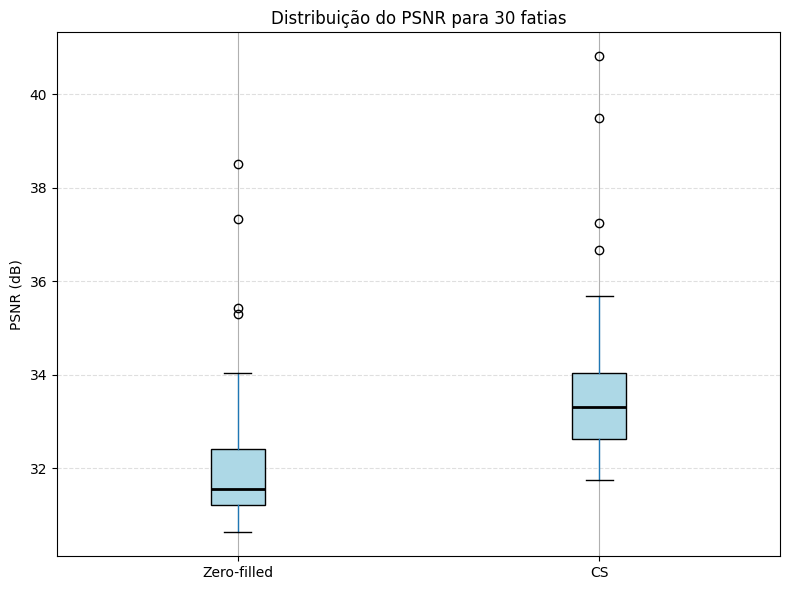


=== TESTE DE SIGNIFICÂNCIA ESTATÍSTICA (Wilcoxon) ===
Estatística W = 0.00
p-valor = 0.0000000009
✅ Diferença estatisticamente significativa (p < 0.05).


In [8]:
# %%
# ============================================================
# 6. Sumário Estatístico e Teste de Wilcoxon
# ============================================================

# Sumário
summary = pd.DataFrame({
    "PSNR (dB)": [
        f"{df_results.psnr_zf.mean():.2f} ± {df_results.psnr_zf.std():.2f}",
        f"{df_results.psnr_cs.mean():.2f} ± {df_results.psnr_cs.std():.2f}",
    ],
    "SSIM": [
        f"{df_results.ssim_zf.mean():.4f} ± {df_results.ssim_zf.std():.4f}",
        f"{df_results.ssim_cs.mean():.4f} ± {df_results.ssim_cs.std():.4f}",
    ],
    "NMSE": [
        f"{df_results.nmse_zf.mean():.4f} ± {df_results.nmse_zf.std():.4f}",
        f"{df_results.nmse_cs.mean():.4f} ± {df_results.nmse_cs.std():.4f}",
    ],
    "Tempo CS (s)": [
        f"{df_results.time_cs.mean():.3f} ± {df_results.time_cs.std():.3f}",
        f"{df_results.time_cs.mean():.3f} ± {df_results.time_cs.std():.3f}",
    ]
}, index=["Zero-filled", "Compressed Sensing (Wavelet + TV)"])

print("\n=== SUMÁRIO COMPARATIVO (Wavelet + TV, 30 imagens) ===\n")
print(summary)

# Boxplot
plt.figure(figsize=(8, 6))
df_box = pd.DataFrame({'Zero-filled': df_results['psnr_zf'], 'CS': df_results['psnr_cs']})
df_box.boxplot(patch_artist=True, 
               boxprops=dict(facecolor='lightblue'),
               medianprops=dict(color='black', linewidth=2))
plt.title('Distribuição do PSNR para 30 fatias')
plt.ylabel('PSNR (dB)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('boxplot_psnr_comparacao.png', dpi=150)
plt.show()

# Teste de Wilcoxon
from scipy.stats import wilcoxon
stat, p_val = wilcoxon(df_results['psnr_zf'], df_results['psnr_cs'], alternative='less')
print("\n=== TESTE DE SIGNIFICÂNCIA ESTATÍSTICA (Wilcoxon) ===")
print(f"Estatística W = {stat:.2f}")
print(f"p-valor = {p_val:.10f}")
if p_val < 0.05:
    print("✅ Diferença estatisticamente significativa (p < 0.05).")
else:
    print("⚠️  Diferença não significativa.")

In [9]:
# %%
# ============================================================
# 7. Grid Search Estendido (com T_REF fixo)
# ============================================================

def grid_search_parameters_extended(dataset, device, T_ref,
                                    wavelet_values=None,
                                    tv_values=None,
                                    n_images=10):
    """
    Grid search com faixa estendida para confirmar o ótimo.
    """
    if wavelet_values is None:
        wavelet_values = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]
    if tv_values is None:
        tv_values = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]

    results = []
    for lw in wavelet_values:
        for ltv in tv_values:
            print(f"\nλw={lw:.5f} | λtv={ltv:.5f}")
            cfg = CSConfig(
                lambda_wavelet_start=lw, lambda_wavelet_end=lw*0.25,
                lambda_tv_start=ltv, lambda_tv_end=ltv*0.25,
                max_iter=100,
                tv_inner_iter=5,
                use_continuation=True
            )
            rec = FISTA(cfg)
            psnrs = []
            for idx in range(min(n_images, len(dataset))):
                gt = dataset[idx].to(device)
                # Usa t = T_ref para a máscara mais cheia (constante)
                mask = create_mask_t(gt.shape, T_ref, T_ref, device, seed=42+idx)
                kspace_us = MRIOperator(mask).forward(gt)
                x, _, _ = rec.solve(kspace_us, mask)
                p, _, _ = compute_metrics(gt.cpu().numpy(), x.cpu().numpy())
                psnrs.append(p)
            mean_psnr = np.mean(psnrs)
            results.append({"lw": lw, "ltv": ltv, "psnr": mean_psnr})
            print(f"  PSNR médio: {mean_psnr:.2f} dB")

    df_grid = pd.DataFrame(results)
    best = df_grid.loc[df_grid.psnr.idxmax()]
    print("\n=== MELHORES PARÂMETROS (GRID ESTENDIDO) ===")
    print(best)
    return df_grid

# Executa (pode levar alguns minutos)
print("Rodando grid search estendido com 10 imagens...")
print("Faixa: λw = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]")
print("       λtv = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]\n")

df_grid_ext = grid_search_parameters_extended(
    dataset, device, T_REF,
    wavelet_values=[0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050],
    tv_values=[0.00005, 0.0001, 0.0002, 0.0005, 0.001],
    n_images=10
)

df_grid_ext.to_csv("grid_search_extended.csv", index=False)
print("\n=== TOP 10 RESULTADOS ===")
display(df_grid_ext.sort_values("psnr", ascending=False).head(10))

Rodando grid search estendido com 10 imagens...
Faixa: λw = [0.005, 0.010, 0.015, 0.020, 0.030, 0.040, 0.050]
       λtv = [0.00005, 0.0001, 0.0002, 0.0005, 0.001]


λw=0.00500 | λtv=0.00005
  PSNR médio: 33.14 dB

λw=0.00500 | λtv=0.00010
  PSNR médio: 33.13 dB

λw=0.00500 | λtv=0.00020
  PSNR médio: 33.11 dB

λw=0.00500 | λtv=0.00050
  PSNR médio: 33.08 dB

λw=0.00500 | λtv=0.00100
  PSNR médio: 33.00 dB

λw=0.01000 | λtv=0.00005
  PSNR médio: 33.17 dB

λw=0.01000 | λtv=0.00010
  PSNR médio: 33.16 dB

λw=0.01000 | λtv=0.00020
  PSNR médio: 33.16 dB

λw=0.01000 | λtv=0.00050
  PSNR médio: 33.14 dB

λw=0.01000 | λtv=0.00100
  PSNR médio: 33.11 dB

λw=0.01500 | λtv=0.00005
  PSNR médio: 33.17 dB

λw=0.01500 | λtv=0.00010
  PSNR médio: 33.17 dB

λw=0.01500 | λtv=0.00020
  PSNR médio: 33.17 dB

λw=0.01500 | λtv=0.00050
  PSNR médio: 33.16 dB

λw=0.01500 | λtv=0.00100
  PSNR médio: 33.14 dB

λw=0.02000 | λtv=0.00005
  PSNR médio: 33.17 dB

λw=0.02000 | λtv=0.00010
  PSNR médio: 33.17 dB

λ

,lw,ltv,psnr
10,0.015,0.00005,33.174110
11,0.015,0.00010,33.172863
12,0.015,0.00020,33.167938
15,0.020,0.00005,33.167031
16,0.020,0.00010,33.166480
5,0.010,0.00005,33.165946
6,0.010,0.00010,33.163071
17,0.020,0.00020,33.162632
13,0.015,0.00050,33.157885
7,0.010,0.00020,33.156077


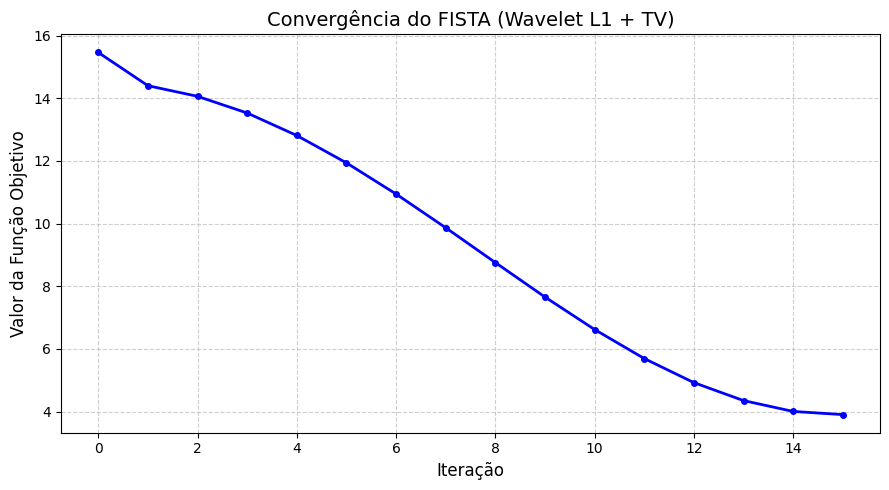

Objetivo final: 3.9047 | Iterações: 16


In [10]:
# %%
# ============================================================
# 8. Curva de Convergência do FISTA
# ============================================================

def plot_convergence(dataset, idx, config, T_ref, device):
    gt = dataset[idx].to(device)
    mask = create_mask_t(gt.shape, T_ref, T_ref, device)
    operator = MRIOperator(mask)
    kspace_us = operator.forward(gt)

    rec = FISTA(config)
    _, _, obj_hist = rec.solve(kspace_us, mask)

    plt.figure(figsize=(9, 5))
    plt.plot(obj_hist, 'b-', linewidth=2, marker='o', markersize=4)
    plt.xlabel('Iteração', fontsize=12)
    plt.ylabel('Valor da Função Objetivo', fontsize=12)
    plt.title('Convergência do FISTA (Wavelet L1 + TV)', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig('convergencia_fista.png', dpi=150)
    plt.show()
    print(f"Objetivo final: {obj_hist[-1]:.4f} | Iterações: {len(obj_hist)}")

# Plota para a primeira fatia
plot_convergence(dataset, idx=0, config=config, T_ref=T_REF, device=device)

=== AVALIANDO ACELERAÇÃO ===
Valores de t: [20, 40, 60, 80, 100, 120]
T_ref fixo = 100



Acelerações:   0%|          | 0/6 [00:00<?, ?it/s]


=== QUALIDADE vs ACELERAÇÃO (CORRIGIDO) ===

  t  PSNR_mean  PSNR_std  SSIM_mean  SSIM_std
 20  52.748729  0.106214   0.997622  0.000216
 40  52.748729  0.106214   0.997622  0.000216
 60  52.733888  0.107619   0.997616  0.000217
 80  50.297106  0.357080   0.996439  0.000413
100  33.167298  0.685228   0.891124  0.010046
120  33.167298  0.685228   0.891124  0.010046


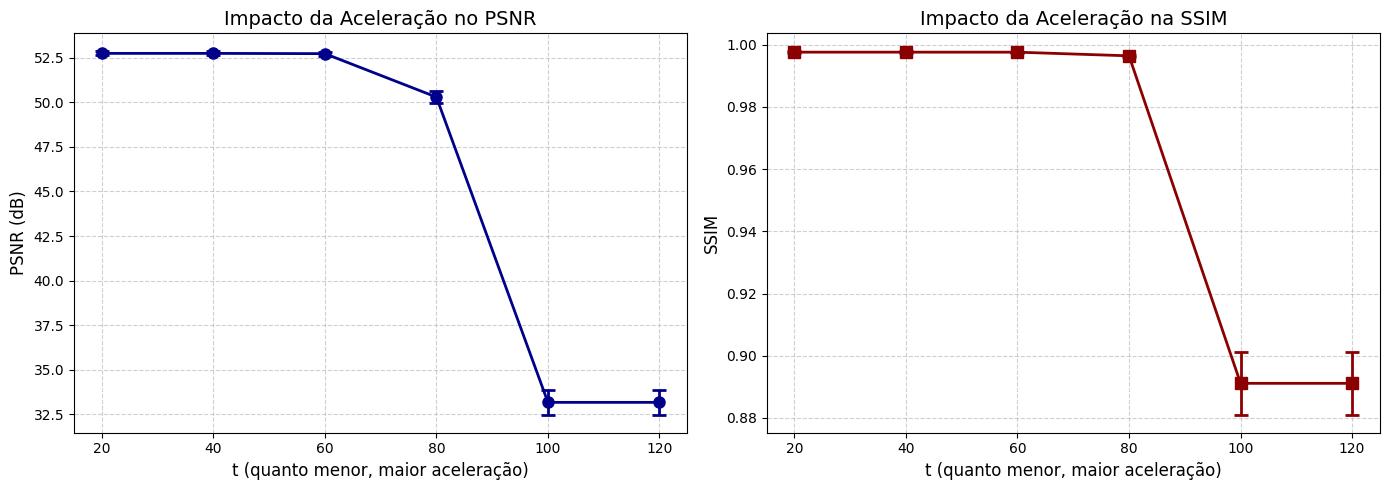

In [11]:
# %%
# ============================================================
# 9. Estudo da Aceleração (t variável, T_ref fixo)
# ============================================================

def evaluate_acceleration(dataset, t_values, T_ref, config, n_images=10, device='cuda'):
    results = []
    for t_val in tqdm(t_values, desc="Acelerações"):
        psnrs, ssims = [], []
        for idx in range(min(n_images, len(dataset))):
            gt = dataset[idx].to(device)
            # t varia, T_ref fixo → máscaras diferentes
            mask = create_mask_t(gt.shape, t_val, T_ref, device, seed=42 + idx)
            operator = MRIOperator(mask)
            kspace_us = operator.forward(gt)

            rec = FISTA(config)
            x, _, _ = rec.solve(kspace_us, mask)

            p, s, _ = compute_metrics(gt.cpu().numpy(), x.cpu().numpy())
            psnrs.append(p)
            ssims.append(s)

        results.append({
            't': t_val,
            'PSNR_mean': np.mean(psnrs),
            'PSNR_std': np.std(psnrs),
            'SSIM_mean': np.mean(ssims),
            'SSIM_std': np.std(ssims)
        })
    return pd.DataFrame(results)

# Valores de t a testar (quanto menor t, maior aceleração)
t_values = [20, 40, 60, 80, 100, 120]  # t=100 → T_ref → máscara cheia

print("=== AVALIANDO ACELERAÇÃO ===")
print(f"Valores de t: {t_values}")
print(f"T_ref fixo = {T_REF}\n")

df_accel = evaluate_acceleration(dataset, t_values, T_REF, config, n_images=10, device=device)

print("\n=== QUALIDADE vs ACELERAÇÃO (CORRIGIDO) ===\n")
print(df_accel.to_string(index=False))

# Gráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.errorbar(df_accel['t'], df_accel['PSNR_mean'], 
             yerr=df_accel['PSNR_std'], fmt='o-', capsize=5, capthick=2,
             linewidth=2, color='darkblue', markersize=8)
ax1.set_xlabel('t (quanto menor, maior aceleração)', fontsize=12)
ax1.set_ylabel('PSNR (dB)', fontsize=12)
ax1.set_title('Impacto da Aceleração no PSNR', fontsize=14)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.set_xlim(min(t_values)-5, max(t_values)+5)

ax2.errorbar(df_accel['t'], df_accel['SSIM_mean'], 
             yerr=df_accel['SSIM_std'], fmt='s-', capsize=5, capthick=2,
             linewidth=2, color='darkred', markersize=8)
ax2.set_xlabel('t (quanto menor, maior aceleração)', fontsize=12)
ax2.set_ylabel('SSIM', fontsize=12)
ax2.set_title('Impacto da Aceleração na SSIM', fontsize=14)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.set_xlim(min(t_values)-5, max(t_values)+5)

plt.tight_layout()
plt.savefig('aceleracao_vs_qualidade.png', dpi=150)
plt.show()

Verificando a variação do número de raios com t:

t =   0  →  amostrados ≈ 16384  (de 16384)
t =  20  →  amostrados ≈ 16384  (de 16384)
t =  40  →  amostrados ≈ 16384  (de 16384)
t =  60  →  amostrados ≈ 16318  (de 16384)
t =  80  →  amostrados ≈ 14769  (de 16384)
t = 100  →  amostrados ≈ 8856  (de 16384)
t = 120  →  amostrados ≈ 8856  (de 16384)


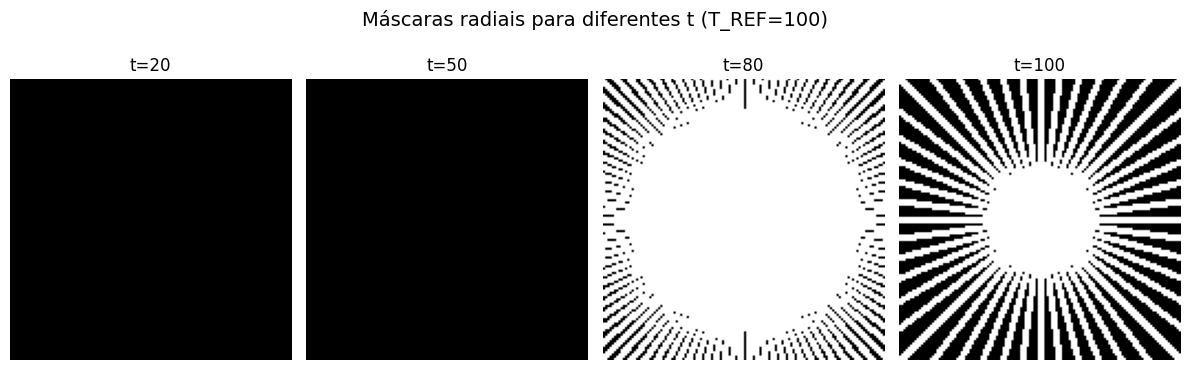

In [12]:
# %%
# ============================================================
# 10. Verificação: número de raios varia com t
# ============================================================

H, W = 128, 128
device = 'cpu'

print("Verificando a variação do número de raios com t:\n")
for t in [0, 20, 40, 60, 80, 100, 120]:
    mask = create_mask_t((H, W), t, T_REF, device)
    # Conta quantos pontos são diferentes de zero (aproximado)
    num_amostrados = torch.sum(mask).item()
    print(f"t = {t:3d}  →  amostrados ≈ {num_amostrados:4.0f}  (de {H*W})")

# Mostra algumas máscaras
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for i, t in enumerate([20, 50, 80, 100]):
    mask = create_mask_t((H, W), t, T_REF, device)
    axes[i].imshow(mask, cmap='gray')
    axes[i].set_title(f't={t}')
    axes[i].axis('off')
plt.suptitle(f'Máscaras radiais para diferentes t (T_REF={T_REF})', fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# %%
# ============================================================
# 11. TABELA COMPARATIVA FINAL (Apenas Baseline CS)
# ============================================================

zf_psnr_mean = df_results['psnr_zf'].mean()
zf_psnr_std = df_results['psnr_zf'].std()
zf_ssim_mean = df_results['ssim_zf'].mean()
zf_ssim_std = df_results['ssim_zf'].std()
zf_nmse_mean = df_results['nmse_zf'].mean()
zf_nmse_std = df_results['nmse_zf'].std()

cs_psnr_mean = df_results['psnr_cs'].mean()
cs_psnr_std = df_results['psnr_cs'].std()
cs_ssim_mean = df_results['ssim_cs'].mean()
cs_ssim_std = df_results['ssim_cs'].std()
cs_nmse_mean = df_results['nmse_cs'].mean()
cs_nmse_std = df_results['nmse_cs'].std()
cs_time_mean = df_results['time_cs'].mean()
cs_time_std = df_results['time_cs'].std()

table_data = {
    "Método": ["Zero-filled", "Compressed Sensing (Wavelet+TV)"],
    "PSNR (dB) ↑": [
        f"{zf_psnr_mean:.2f} ± {zf_psnr_std:.2f}",
        f"{cs_psnr_mean:.2f} ± {cs_psnr_std:.2f}"
    ],
    "SSIM ↑": [
        f"{zf_ssim_mean:.4f} ± {zf_ssim_std:.4f}",
        f"{cs_ssim_mean:.4f} ± {cs_ssim_std:.4f}"
    ],
    "NMSE ↓": [
        f"{zf_nmse_mean:.4f} ± {zf_nmse_std:.4f}",
        f"{cs_nmse_mean:.4f} ± {cs_nmse_std:.4f}"
    ],
    "Tempo (s) ↓": [
        "< 0.01",
        f"{cs_time_mean:.3f} ± {cs_time_std:.3f}"
    ]
}

df_final_table = pd.DataFrame(table_data)
print("\n=== TABELA COMPARATIVA FINAL (para o artigo) ===\n")
print(df_final_table.to_string(index=False))

df_final_table.to_csv("tabela_resultados_baseline.csv", index=False)

# Código LaTeX
latex_code = df_final_table.to_latex(
    index=False,
    escape=False,
    column_format="lcccc",
    caption="Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV). Valores reportados como média $\\pm$ desvio padrão para 30 fatias cerebrais.",
    label="tab:baseline_comparison"
)

print("\n--- CÓDIGO LaTeX PARA O ARTIGO ---\n")
print(latex_code)

with open("tabela_latex_baseline.txt", "w") as f:
    f.write(latex_code)


=== TABELA COMPARATIVA FINAL (para o artigo) ===

                         Método  PSNR (dB) ↑          SSIM ↑          NMSE ↓   Tempo (s) ↓
                    Zero-filled 32.33 ± 1.95 0.8138 ± 0.0493 0.0159 ± 0.0054        < 0.01
Compressed Sensing (Wavelet+TV) 33.92 ± 2.11 0.9094 ± 0.0302 0.0114 ± 0.0050 1.245 ± 0.128

--- CÓDIGO LaTeX PARA O ARTIGO ---

\begin{table}
\caption{Comparação quantitativa entre Zero-filled e o baseline de Compressed Sensing (Wavelet L1 + TV). Valores reportados como média $\pm$ desvio padrão para 30 fatias cerebrais.}
\label{tab:baseline_comparison}
\begin{tabular}{lcccc}
\toprule
Método & PSNR (dB) ↑ & SSIM ↑ & NMSE ↓ & Tempo (s) ↓ \\
\midrule
Zero-filled & 32.33 ± 1.95 & 0.8138 ± 0.0493 & 0.0159 ± 0.0054 & < 0.01 \\
Compressed Sensing (Wavelet+TV) & 33.92 ± 2.11 & 0.9094 ± 0.0302 & 0.0114 ± 0.0050 & 1.245 ± 0.128 \\
\bottomrule
\end{tabular}
\end{table}



Usando fatia índice 15 (mais próxima da média)


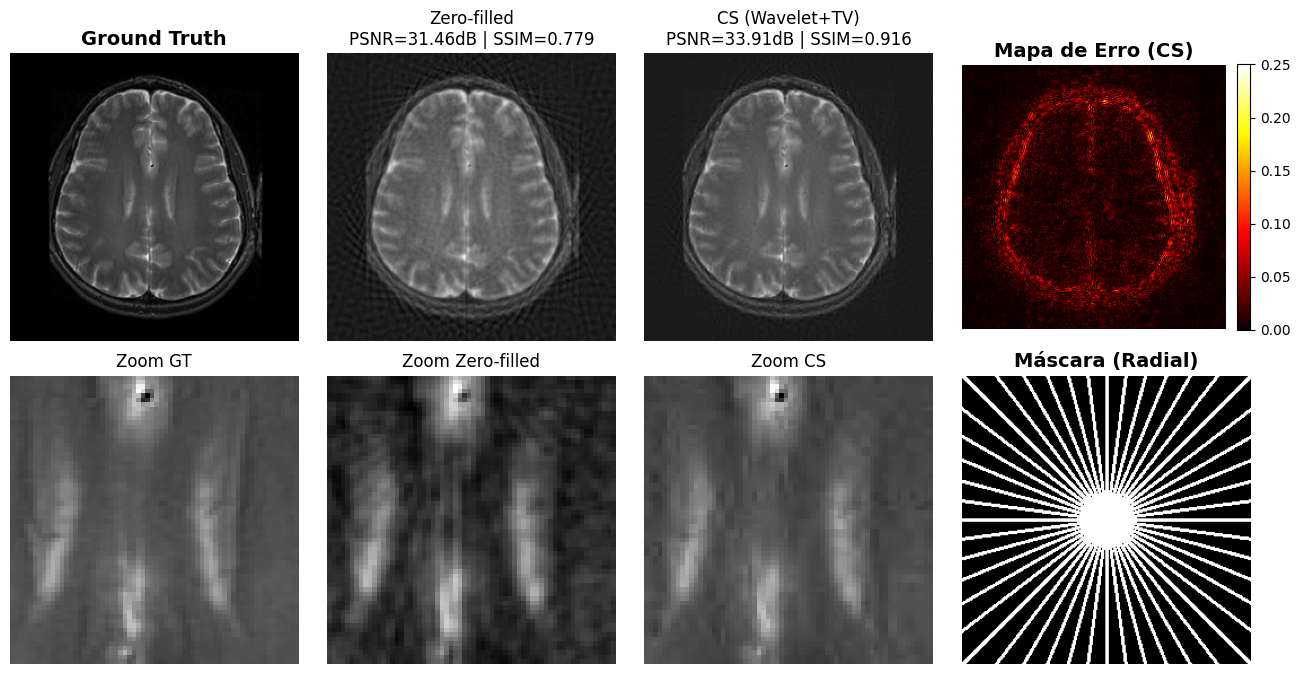

Figura salva como 'figura_resultados_baseline.png'


In [14]:
# %%
# ============================================================
# 12. FIGURA DE ALTA QUALIDADE PARA O ARTIGO
# ============================================================

# Escolhe uma fatia representativa (a que tiver PSNR mais próximo da média)
idx_rep = np.argmin(np.abs(df_results['psnr_cs'] - df_results['psnr_cs'].mean()))
print(f"Usando fatia índice {idx_rep} (mais próxima da média)")

gt = dataset[idx_rep].to(device)
mask = create_mask_t(gt.shape, T_REF, T_REF, device)
operator = MRIOperator(mask)
kspace_us = operator.forward(gt)

zf = operator.zero_filled(kspace_us)
rec = FISTA(config)
cs_img, _, _ = rec.solve(kspace_us, mask)

gt_np = gt.cpu().numpy()
zf_np = zf.cpu().numpy()
cs_np = cs_img.cpu().numpy()
mask_np = mask.cpu().numpy()

psnr_zf, ssim_zf, _ = compute_metrics(gt_np, zf_np)
psnr_cs, ssim_cs, _ = compute_metrics(gt_np, cs_np)

# Plot profissional
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 4, hspace=0.1, wspace=0.1)

# Linha 1: imagens
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(gt_np, cmap='gray')
ax1.set_title('Ground Truth', fontsize=14, fontweight='bold')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(zf_np, cmap='gray')
ax2.set_title(f'Zero-filled\nPSNR={psnr_zf:.2f}dB | SSIM={ssim_zf:.3f}', fontsize=12)
ax2.axis('off')

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(cs_np, cmap='gray')
ax3.set_title(f'CS (Wavelet+TV)\nPSNR={psnr_cs:.2f}dB | SSIM={ssim_cs:.3f}', fontsize=12)
ax3.axis('off')

ax4 = fig.add_subplot(gs[0, 3])
diff_plot = np.abs(gt_np - cs_np)
im4 = ax4.imshow(diff_plot, cmap='hot', vmin=0, vmax=0.25)
ax4.set_title('Mapa de Erro (CS)', fontsize=14, fontweight='bold')
ax4.axis('off')
plt.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)

# Linha 2: zoom
zoom_frac = 0.25
h, w = gt_np.shape
h_zoom = int(h * zoom_frac)
w_zoom = int(w * zoom_frac)
start_h = h//2 - h_zoom//2
start_w = w//2 - w_zoom//2

ax5 = fig.add_subplot(gs[1, 0])
ax5.imshow(gt_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax5.set_title('Zoom GT', fontsize=12)
ax5.axis('off')

ax6 = fig.add_subplot(gs[1, 1])
ax6.imshow(zf_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax6.set_title('Zoom Zero-filled', fontsize=12)
ax6.axis('off')

ax7 = fig.add_subplot(gs[1, 2])
ax7.imshow(cs_np[start_h:start_h+h_zoom, start_w:start_w+w_zoom], cmap='gray')
ax7.set_title('Zoom CS', fontsize=12)
ax7.axis('off')

ax8 = fig.add_subplot(gs[1, 3])
ax8.imshow(mask_np, cmap='gray')
ax8.set_title('Máscara (Radial)', fontsize=14, fontweight='bold')
ax8.axis('off')

plt.tight_layout()
plt.savefig('figura_resultados_baseline.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figura salva como 'figura_resultados_baseline.png'")